# EDA dan cleaning komentar YouTube

Notebook ini menyiapkan dataset untuk eksperimen **ANN, SVM, dan Multinomial Naive Bayes**. Urutannya: membaca data → EDA pada data asli → keputusan cleaning → eksekusi → pemeriksaan hasil → ekspor.

**Tidak ada training, TF-IDF, atau pembagian train/test di notebook ini.** Dataset sumber tidak diubah. Label `1` diduga promosi judi dan `0` komentar biasa berdasarkan contoh; arti label dan metode anotasi harus dikonfirmasi dari sumber dataset. `predicted_label` adalah keluaran prediksi yang sudah ada, bukan label rujukan yang otomatis benar.

Jalankan sel dari atas ke bawah. Dependensi: Python, pandas, dan IPython (tersedia pada lingkungan Jupyter). Grafik dibuat sebagai SVG tanpa library plotting tambahan.

Sumber dataset awal: [Judi Online — Kaggle](https://www.kaggle.com/datasets/yaemico/judionline), identifier `yaemico/judionline`, berdasarkan informasi anggota kelompok. Catatan sumber dan batas verifikasi tersedia di [dataset/README.md](dataset/README.md). Komentar sintetis dibuat terpisah oleh kelompok, bukan diperoleh dari Kaggle.


In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import html
import json
import re
import unicodedata
import pandas as pd
from IPython.display import display, Markdown, SVG

pd.set_option('display.max_colwidth', 140)
pd.set_option('display.max_columns', 15)

# Mendukung notebook di root proyek atau subfolder notebooks.
PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / 'dataset').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
INPUT_PATH = PROJECT_DIR / 'dataset' / 'data_komentar_dengan_prediksi - data_komentar_dengan_prediksi(2).csv'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'cleaning'
if not INPUT_PATH.is_file():
    raise FileNotFoundError(f'Dataset tidak ditemukan: {INPUT_PATH}. Sesuaikan PROJECT_DIR.')
SOURCE_SHA256 = hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest()
print('Sumber:', INPUT_PATH.relative_to(PROJECT_DIR))
print('SHA-256:', SOURCE_SHA256)

Sumber: dataset\data_komentar_dengan_prediksi - data_komentar_dengan_prediksi(2).csv
SHA-256: 6a31d1718093e45ad46b8083e94f64cc11f101dbe689b4428c0f5330bd0228e8


## 1. Baca dan periksa struktur data

Semua kolom dibaca sebagai teks agar ID dan tanggal tidak berubah. Nomor `source_row` menunjuk urutan record CSV mulai dari 1, tidak termasuk header; ini bukan nomor baris fisik jika komentar mengandung newline.

In [2]:
raw = pd.read_csv(INPUT_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
required = {'komentar', 'label'}
assert required.issubset(raw.columns), f'Kolom wajib tidak lengkap: {required - set(raw.columns)}'
assert not raw.columns.duplicated().any(), 'Nama kolom ganda ditemukan.'
source_columns = raw.columns.tolist()
df = raw.copy()
df.insert(0, 'source_row', range(1, len(df) + 1))
print(f'{len(df):,} record, {len(source_columns)} kolom sumber')
display(raw.head())
display(pd.DataFrame({'tipe': raw.dtypes.astype(str), 'nilai_unik': raw.nunique()}))

10,230 record, 9 kolom sumber


,video_id,title,channel_name,tanggal,author,komentar,label,komentar_clean,predicted_label
0,f8UEkmYXlzA,SKAKMAT AHOK,Pandji Pragiwaksono,1.745.412.234.123.970,TerranceNoelle-o9i,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1,makin yakin abis baca review lain tentang 𝐒𝐆𝐈𝟖𝟖 .,0
1,XI8K0-_kbHc,GAK NYANGKA BISA BEGINI! PENGENDARA DIJALAN SAMPAI BINGUNG LIHAT HUMMER EV | GLAMOUR AUTO BOUTIQUE,Jejelogy,1.739.601.493.342.000,deraatvexplorerriders.2113,Paling suka model H2 😍🔥,0,suka model h2,0
2,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.772.479.808.090,risqokurniadi7208,Mobilnya udah hancur 🥺,0,mobilnya udah hancur,0
3,QpXcKzQInXg,Review Mobil Drift Seharga Super Car | BRZ V8 Obell,Garasi Drift,1.738.825.556.100.780,LorrianeDotson,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin sultan,1
4,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.858.865.953.920,Elpoco7365,Semoga lekas recover mobilnya mas Dipo,0,semoga lekas recover mobilnya mas dipo,0


,tipe,nilai_unik
video_id,str,32
title,str,32
channel_name,str,18
tanggal,str,7289
author,str,9267
komentar,str,9001
label,str,2
komentar_clean,str,8903
predicted_label,str,2


## 2. EDA: kelengkapan dan distribusi label

Label hanya dinyatakan valid jika setelah trim bernilai `0` atau `1`. Nilai kosong, termasuk teks yang hanya berisi spasi, dihitung terpisah. Grafik dan tabel berikut memakai data sumber sebelum cleaning.

,kosong_atau_spasi
video_id,0
title,0
channel_name,0
tanggal,0
author,0
komentar,0
label,0
komentar_clean,0
predicted_label,0


,jumlah,persen
label,,
0,6021,58.86
1,4209,41.14


Label di luar 0/1 setelah trim: 0


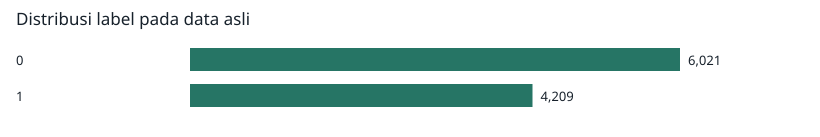

In [3]:
missing = raw.apply(lambda col: col.str.strip().eq('').sum()).rename('kosong_atau_spasi').to_frame()
display(missing)
label_summary = df['label'].value_counts(dropna=False).rename_axis('label').to_frame('jumlah')
label_summary['persen'] = (label_summary['jumlah'] / len(df) * 100).round(2)
display(label_summary)
print('Label di luar 0/1 setelah trim:', int((~df['label'].str.strip().isin(['0', '1'])).sum()))


def bar_svg(series, title):
    series = series.astype(int)
    width, left, row_h = 820, 190, 36
    height = 65 + row_h * len(series)
    maximum = max(int(series.max()), 1) if len(series) else 1
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" role="img" aria-label="{html.escape(title)}">',
             '<rect width="100%" height="100%" fill="white"/>',
             f'<text x="16" y="25" font-family="sans-serif" font-size="17" fill="#17212b">{html.escape(title)}</text>']
    for i, (name, value) in enumerate(series.items()):
        y = 48 + i * row_h
        bar_width = value / maximum * 490
        parts += [f'<text x="16" y="{y+17}" font-family="sans-serif" font-size="13" fill="#17212b">{html.escape(str(name))}</text>',
                  f'<rect x="{left}" y="{y}" width="{bar_width:.1f}" height="23" fill="#267565"/>',
                  f'<text x="{left+bar_width+8:.1f}" y="{y+17}" font-family="sans-serif" font-size="13" fill="#17212b">{value:,}</text>']
    parts.append('</svg>')
    display(SVG(''.join(parts)))

bar_svg(label_summary['jumlah'], 'Distribusi label pada data asli')

## 3. EDA: panjang dan contoh komentar

Panjang karakter dan jumlah token berbasis spasi membantu mengenali komentar sangat pendek/panjang. Angka ini deskriptif, bukan dasar untuk otomatis membuang komentar. Contoh dipilih secara reproducible dengan seed tetap.

karakter                                       ... token_spasi        \
         count   mean    std  min   25%   50%   75%  ...        mean   std   
label                                                ...                     
0       6021.0  36.13  16.83  6.0  22.0  34.0  48.0  ...        6.17  2.85   
1       4209.0  45.94  20.65  9.0  33.0  44.0  55.0  ...        8.10  3.58   

                                  
       min  25%  50%   75%   max  
label                             
0      1.0  4.0  6.0   8.0  16.0  
1      1.0  6.0  8.0  10.0  43.0  

[2 rows x 16 columns]

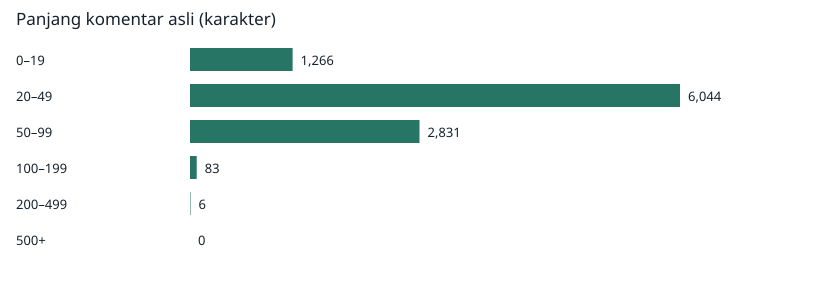

Contoh label 0:


,source_row,komentar,label
8722,8723,Wkwkwkwk kena schoolar mate😂😂😂,0
5939,5940,5:23 saran dari ane suara agak dalem bg\nbiar sukses terus,0
4783,4784,Gass bang modif motor,0
6235,6236,jersey kiper nya dong bang,0
10008,10009,Bang bahas mobil baru Farel dong....,0


Contoh label 1:


,source_row,komentar,label
2647,2648,Dah ah tobat gk maenGaruda-hoki lg abis maxwin soalnya😭,1
350,351,Gokil! Bangga banget jadi bagian dari 🔥⚡ALEXIS17⚡?🔥,1
5814,5815,konten ! keren banget menjelaskannya ! main bagus bang 𝗪𝗘𝗧𝗢𝗡𝟴𝟴,1
459,460,"gak nyangka 𝘼𝙇𝙀𝙓𝙄𝙎17 se-booming , keren abis ! beneran ?",1
6335,6336,Gak nyangka bakal nemu tempat segokil 𝓟𝓤𝓛𝓐𝓤𝓦𝓘𝓝.,1


In [4]:
lengths = pd.DataFrame({
    'label': df['label'],
    'karakter': df['komentar'].str.len(),
    'token_spasi': df['komentar'].str.split().str.len(),
})
display(lengths.groupby('label')[['karakter', 'token_spasi']].describe().round(2))
bins = [0, 20, 50, 100, 200, 500, float('inf')]
bucket = pd.cut(lengths['karakter'], bins=bins, right=False,
                labels=['0–19', '20–49', '50–99', '100–199', '200–499', '500+'])
bar_svg(bucket.value_counts(sort=False), 'Panjang komentar asli (karakter)')
for label, group in df.groupby('label', sort=True):
    print(f'Contoh label {label}:')
    display(group[['source_row', 'komentar', 'label']].sample(n=min(5, len(group)), random_state=42))

## 4. EDA: duplikat dan konflik label

Duplikat seluruh record berbeda dari duplikat teks. Teks yang sama bisa berasal dari video atau author berbeda. Konflik berarti teks identik memiliki lebih dari satu label; notebook tidak menebak label yang benar.

In [5]:
duplicate_summary = pd.DataFrame({
    'pemeriksaan': ['Record identik (semua kolom sumber)', 'Teks komentar identik'],
    'duplikat_tambahan': [int(raw.duplicated().sum()), int(df.duplicated('komentar').sum())],
})
if 'komentar_clean' in df.columns:
    duplicate_summary.loc[len(duplicate_summary)] = ['Teks komentar_clean identik', int(df.duplicated('komentar_clean').sum())]
display(duplicate_summary)
raw_label_counts = df.assign(label_check=df['label'].str.strip()).groupby('komentar')['label_check'].nunique()
raw_conflict_texts = raw_label_counts[raw_label_counts > 1].index
raw_conflicts = df[df['komentar'].isin(raw_conflict_texts)].sort_values('komentar')
print('Kelompok teks asli dengan label bertentangan:', len(raw_conflict_texts))
display(raw_conflicts[['source_row', 'komentar', 'label']])
print('Contoh teks paling sering berulang:')
display(df['komentar'].value_counts().head(10).rename_axis('komentar').to_frame('jumlah'))

,pemeriksaan,duplikat_tambahan
0,Record identik (semua kolom sumber),0
1,Teks komentar identik,1229
2,Teks komentar_clean identik,1327


Kelompok teks asli dengan label bertentangan: 1


,source_row,komentar,label
1858,1859,bused mewah banget,1
6774,6775,bused mewah banget,0


Contoh teks paling sering berulang:


,jumlah
komentar,
"terbaik kak , salam weton88",7
"modal receh makswin , gg sih",7
"modal receh , lgsng mekswin gg",7
emang gak se-terpercaya alexis17 sih .,6
"cakep kali 𝗪𝗘𝗧𝗢𝗡𝟴𝟴 , bravo ..",6
konten ! keren banget menjelaskannya ! main bagus bang 𝗪𝗘𝗧𝗢𝗡𝟴𝟴,6
"kerennn contentnya bang , cari situs 𝗪𝗘𝗧𝗢𝗡𝟴𝟴",6
𝗪𝗘𝗧𝗢𝗡𝟴𝟴 uhuy !,6
"swert bonanja gacir , modal jepek",6


## 5. EDA: metadata, Unicode, dan prediksi lama

Metadata membantu memahami cakupan sumber dan merancang evaluasi selanjutnya. Format tanggal hanya diperiksa, tidak dikonversi karena format angka bertitik belum diketahui maknanya. Perbedaan `label` dan `predicted_label` bukan bukti bahwa salah satunya pasti salah. Nilai kecocokan prediksi lama tidak boleh dilaporkan sebagai performa eksperimen baru.

In [6]:
if 'video_id' in df:
    print('Video unik:', df['video_id'].nunique())
if 'channel_name' in df:
    print('Channel unik:', df['channel_name'].nunique())
    display(df['channel_name'].value_counts().rename_axis('channel').to_frame('jumlah'))
if 'tanggal' in df:
    date_format = pd.Series({
        'Mirip ISO (YYYY-MM-DD...)': int(df['tanggal'].str.match(r'^\d{4}-\d{2}-\d{2}').sum()),
        'Angka bertitik': int(df['tanggal'].str.fullmatch(r'\d+(?:\.\d+)+').sum()),
        'Kosong': int(df['tanggal'].str.strip().eq('').sum()),
    })
    display(date_format.to_frame('jumlah'))

url_pattern = re.compile(r'(?:https?://|www\.)[^\s<>]+', flags=re.IGNORECASE)
text_signals = pd.Series({
    'Berubah setelah NFKC': int(df['komentar'].map(lambda s: unicodedata.normalize('NFKC', s) != s).sum()),
    'Memiliki digit': int(df['komentar'].str.contains(r'\d', regex=True).sum()),
    'Memiliki URL http/https/www': int(df['komentar'].map(lambda s: bool(url_pattern.search(s))).sum()),
    'Memiliki karakter format Unicode (Cf)': int(df['komentar'].map(lambda s: any(unicodedata.category(c) == 'Cf' for c in s)).sum()),
})
display(text_signals.to_frame('jumlah_komentar'))
if 'predicted_label' in df:
    print('Baris label berbeda dengan predicted_label:', int(df['label'].ne(df['predicted_label']).sum()))
    display(pd.crosstab(df['label'], df['predicted_label'], rownames=['label'], colnames=['prediksi_lama']))

Video unik: 32
Channel unik: 18


,jumlah
channel,
Garasi Drift,1951
GadgetIn,1455
Narasi Newsroom,1453
Fitra Eri,1180
Pandji Pragiwaksono,837
Motomobi,806
Wakil Presiden Republik Indonesia,804
Karbida FC,460
Om Mobi,408


,jumlah
Mirip ISO (YYYY-MM-DD...),2958
Angka bertitik,7272
Kosong,0


,jumlah_komentar
Berubah setelah NFKC,2269
Memiliki digit,4671
Memiliki URL http/https/www,1
Memiliki karakter format Unicode (Cf),226


Baris label berbeda dengan predicted_label: 86


prediksi_lama,0,1
label,,
0,5995,26
1,60,4149


## 6. Keputusan cleaning berdasarkan EDA

- Gunakan `komentar` asli dan simpan hasil baru di `komentar_processed`; jangan menimpa teks asli atau mengandalkan preprocessing lama yang belum terdokumentasi.
- Normalisasi **NFKC**, huruf kecil, hapus karakter format Unicode kategori `Cf`, ubah karakter kontrol menjadi spasi, lalu rapikan spasi. NFKC mengubah sejumlah huruf dekoratif, bukan seluruh variasi tulisan atau homoglyph.
- Ganti URL yang diawali `http://`, `https://`, atau `www.` menjadi `<url>`. Domain polos belum dicakup. Angka, tanda baca, dan emoji tetap disimpan. Stemming dan stopword removal tidak dilakukan pada baseline ini.
- Pisahkan record dengan teks kosong setelah cleaning atau label di luar `0/1`.
- Pisahkan **semua** record dalam kelompok teks hasil cleaning yang berlabel bertentangan. Tidak dilakukan koreksi label otomatis.
- Untuk kelompok teks hasil cleaning yang sama dan label konsisten, simpan record pertama sesuai urutan sumber dan catat jumlah kemunculannya. Audit menyimpan seluruh record yang disisihkan.
- Metadata dan tanggal tidak dipakai sebagai fitur di tahap ini. `predicted_label` dan `komentar_clean` lama tidak disertakan dalam dataset hasil cleaning.

Deduplicasi menghasilkan dataset berbasis teks unik, sehingga frekuensi asli komentar berubah. Untuk evaluasi nanti, pastikan juga komentar template yang mirip tidak bocor antarbagian; deduplikasi persis belum menjamin bebas kemiripan. Pertimbangkan pembagian berdasarkan video jika tujuan evaluasinya generalisasi ke video baru.

In [7]:
def clean_comment(text):
    text = unicodedata.normalize('NFKC', text)
    text = ''.join('' if unicodedata.category(c) == 'Cf' else c for c in text)
    text = ''.join(' ' if unicodedata.category(c) == 'Cc' else c for c in text)
    text = text.lower()
    text = url_pattern.sub('<url>', text)
    return re.sub(r'\s+', ' ', text).strip()

# Pemeriksaan perilaku yang penting untuk ciri promosi judi.
assert clean_comment('  𝐒𝐆𝐈𝟖𝟖  ') == 'sgi88'
assert clean_comment('ALEXIS-17 ☯') == 'alexis-17 ☯'
assert clean_comment('cek HTTPS://contoh.test/a') == 'cek <url>'
assert clean_comment('a\u200bb\n c') == 'ab c'
assert clean_comment(clean_comment('  𝐒𝐆𝐈𝟖𝟖 HTTPS://contoh.test  ')) == clean_comment('  𝐒𝐆𝐈𝟖𝟖 HTTPS://contoh.test  ')

work = df.copy()
work['label_original'] = work['label']
work['label'] = work['label'].str.strip()
work['komentar_processed'] = work['komentar'].map(clean_comment)
print('Baris yang teksnya berubah:', int(work['komentar'].ne(work['komentar_processed']).sum()))
display(work.loc[work['komentar'].ne(work['komentar_processed']),
                 ['source_row', 'komentar', 'komentar_processed', 'label']].head(12))

Baris yang teksnya berubah: 7032


,source_row,komentar,komentar_processed,label
0,1,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,makin yakin abis baca review lain tentang ✌✌sgi88.,1
1,2,Paling suka model H2 😍🔥,paling suka model h2 😍🔥,0
2,3,Mobilnya udah hancur 🥺,mobilnya udah hancur 🥺,0
3,4,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,░manut88░benar2 bikin aku jadi sultan,1
4,5,Semoga lekas recover mobilnya mas Dipo,semoga lekas recover mobilnya mas dipo,0
6,7,gua udah ga bisa bayangin hidup tanpa ALEXIS-17☯ sih,gua udah ga bisa bayangin hidup tanpa alexis-17☯ sih,1
9,10,Yapping mulu anjir kagak ada jawaban sistematis dan realistis,yapping mulu anjir kagak ada jawaban sistematis dan realistis,0
12,13,Keren bngettttt,keren bngettttt,0
13,14,Diatas GD masi ada ASC monster 😅,diatas gd masi ada asc monster 😅,0
14,15,Makantuh setengah jam,makantuh setengah jam,0


## 7. Eksekusi pemisahan dan deduplikasi

Urutan alasan audit: input tidak valid → konflik label → duplikat → disimpan. Konflik juga diperiksa terhadap label yang tidak valid: jika satu teks memiliki `0` dan label tak dikenal, kelompok validnya ikut ditahan untuk diperiksa.

In [8]:
work['empty_text'] = work['komentar_processed'].eq('')
work['invalid_label'] = ~work['label'].isin(['0', '1'])
nonempty = work.loc[~work['empty_text']]
label_counts = nonempty.groupby('komentar_processed')['label'].nunique()
conflict_keys = label_counts[label_counts > 1].index
work['label_conflict'] = work['komentar_processed'].isin(conflict_keys)
work['status'] = 'candidate'
invalid = work['empty_text'] | work['invalid_label']
work.loc[invalid, 'status'] = 'review_invalid'
work.loc[~invalid & work['label_conflict'], 'status'] = 'review_label_conflict'
candidates = work.loc[work['status'].eq('candidate')]
duplicate_indices = candidates.index[candidates.duplicated('komentar_processed', keep='first')]
work.loc[duplicate_indices, 'status'] = 'duplicate'
work.loc[work['status'].eq('candidate'), 'status'] = 'kept'

frequency = work.groupby('komentar_processed').size()
work['duplicate_count'] = work['komentar_processed'].map(frequency)
retained_columns = ['source_row'] + [c for c in source_columns if c not in {'predicted_label', 'komentar_clean'}]
retained_columns += ['komentar_processed', 'duplicate_count']
cleaned = work.loc[work['status'].eq('kept'), retained_columns].copy().reset_index(drop=True)
cleaned['label'] = cleaned['label'].astype(int)
review = work.loc[work['status'].str.startswith('review_')].copy()

flow = work['status'].value_counts().reindex(['kept', 'duplicate', 'review_label_conflict', 'review_invalid'], fill_value=0)
display(flow.rename_axis('status').to_frame('jumlah'))
print('Kelompok konflik setelah cleaning:', len(conflict_keys))
display(review[['source_row', 'komentar', 'komentar_processed', 'label', 'status']])

,jumlah
status,
kept,8934
duplicate,1294
review_label_conflict,2
review_invalid,0


Kelompok konflik setelah cleaning: 1


,source_row,komentar,komentar_processed,label,status
1858,1859,bused mewah banget,bused mewah banget,1,review_label_conflict
6774,6775,bused mewah banget,bused mewah banget,0,review_label_conflict


## 8. Verifikasi dan EDA setelah cleaning

Pemeriksaan memastikan semua record sumber tercatat di audit, teks hasil akhir tidak kosong atau duplikat, label valid, dan cleaning dapat diulang tanpa mengubah hasil lagi. Ini memeriksa konsistensi proses, bukan membuktikan kebenaran anotasi.

,sebelum,sesudah,persen_sebelum,persen_sesudah
label,,,,
0,6021,6016,58.86,67.34
1,4209,2918,41.14,32.66


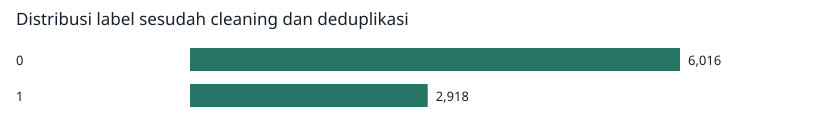

Hasil: 8,934 komentar unik siap untuk tahap pembagian data.
Semua pemeriksaan konsistensi lulus. File sumber tidak berubah.


,source_row,video_id,title,channel_name,tanggal,author,komentar,label,komentar_processed,duplicate_count
0,1,f8UEkmYXlzA,SKAKMAT AHOK,Pandji Pragiwaksono,1.745.412.234.123.970,TerranceNoelle-o9i,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1,makin yakin abis baca review lain tentang ✌✌sgi88.,1
1,2,XI8K0-_kbHc,GAK NYANGKA BISA BEGINI! PENGENDARA DIJALAN SAMPAI BINGUNG LIHAT HUMMER EV | GLAMOUR AUTO BOUTIQUE,Jejelogy,1.739.601.493.342.000,deraatvexplorerriders.2113,Paling suka model H2 😍🔥,0,paling suka model h2 😍🔥,1
2,3,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.772.479.808.090,risqokurniadi7208,Mobilnya udah hancur 🥺,0,mobilnya udah hancur 🥺,1
3,4,QpXcKzQInXg,Review Mobil Drift Seharga Super Car | BRZ V8 Obell,Garasi Drift,1.738.825.556.100.780,LorrianeDotson,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1,░manut88░benar2 bikin aku jadi sultan,1
4,5,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.858.865.953.920,Elpoco7365,Semoga lekas recover mobilnya mas Dipo,0,semoga lekas recover mobilnya mas dipo,1


In [9]:
assert len(work) == len(raw) == int(flow.sum())
assert work['source_row'].is_unique
assert len(cleaned) > 0, 'Tidak ada record yang lolos; periksa data dan aturan cleaning.'
assert cleaned['label'].isin([0, 1]).all()
assert not cleaned['komentar_processed'].str.strip().eq('').any()
assert not cleaned['komentar_processed'].duplicated().any()
assert cleaned['komentar_processed'].map(clean_comment).equals(cleaned['komentar_processed'])
assert not cleaned['komentar_processed'].isin(conflict_keys).any()
assert 'predicted_label' not in cleaned.columns
assert hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest() == SOURCE_SHA256

comparison = pd.concat([
    work['label'].value_counts().rename('sebelum'),
    cleaned['label'].astype(str).value_counts().rename('sesudah'),
], axis=1).fillna(0).astype(int).sort_index()
comparison['persen_sebelum'] = (comparison['sebelum'] / len(work) * 100).round(2)
comparison['persen_sesudah'] = (comparison['sesudah'] / len(cleaned) * 100).round(2)
display(comparison)
bar_svg(comparison['sesudah'], 'Distribusi label sesudah cleaning dan deduplikasi')
print(f'Hasil: {len(cleaned):,} komentar unik siap untuk tahap pembagian data.')
print('Semua pemeriksaan konsistensi lulus. File sumber tidak berubah.')
display(cleaned.head())

## 9. Ekspor hasil

Eksekusi ulang menimpa hanya file hasil dengan nama yang sama di `outputs/cleaning/`. CSV memakai UTF-8 dengan BOM agar karakter mudah dibuka di Excel.

- `komentar_cleaned.csv`: teks unik, metadata record perwakilan, label, dan jumlah kemunculan. Untuk modeling nanti, pilih **hanya `komentar_processed` sebagai X dan `label` sebagai y**. `duplicate_count`, `source_row`, serta metadata bukan fitur baseline.
- `cleaning_review.csv`: record yang perlu diperiksa; jangan gabungkan kembali sebelum keputusan anotasi terdokumentasi.
- `cleaning_audit.csv`: semua record sumber, hasil transformasi, flag, dan keputusan cleaning.
- `cleaning_summary.json`: hitungan, aturan, dan hash sumber untuk reproduksi.

Tahap berikutnya adalah membagi data latih/uji, lalu memasang TF-IDF dan model dalam pipeline. TF-IDF dan pemilihan parameter harus dipelajari hanya dari data latih; data uji tidak dipakai untuk memilih aturan cleaning atau parameter berdasarkan skor.

In [10]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cleaned_path = OUTPUT_DIR / 'komentar_cleaned.csv'
review_path = OUTPUT_DIR / 'cleaning_review.csv'
audit_path = OUTPUT_DIR / 'cleaning_audit.csv'
summary_path = OUTPUT_DIR / 'cleaning_summary.json'
cleaned.to_csv(cleaned_path, index=False, encoding='utf-8-sig')
review.to_csv(review_path, index=False, encoding='utf-8-sig')
work.to_csv(audit_path, index=False, encoding='utf-8-sig')
summary = {
    'source_file': INPUT_PATH.name,
    'source_sha256': SOURCE_SHA256,
    'source_rows': len(raw),
    'cleaned_rows': len(cleaned),
    'status_counts': {str(k): int(v) for k, v in flow.items()},
    'conflicting_clean_text_groups': len(conflict_keys),
    'labels_before': {str(k): int(v) for k, v in work['label'].value_counts().items()},
    'labels_after': {str(k): int(v) for k, v in cleaned['label'].value_counts().items()},
    'cleaning': ['NFKC', 'remove Unicode Cf', 'control characters to spaces', 'lowercase', 'http/https/www URL to <url>', 'collapse whitespace', 'quarantine invalid and conflicting labels', 'deduplicate processed text; keep first source record'],
    'label_meaning_confirmed': False,
    'annotation_method_known': False,
    'training_performed': False,
}
summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

# Pastikan ekspor dapat dibaca ulang tanpa kehilangan karakter atau record.
reloaded = pd.read_csv(cleaned_path, dtype=str, keep_default_na=False, encoding='utf-8-sig')
assert len(reloaded) == len(cleaned)
assert reloaded['komentar_processed'].tolist() == cleaned['komentar_processed'].tolist()
assert reloaded['label'].tolist() == cleaned['label'].astype(str).tolist()
assert hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest() == SOURCE_SHA256
for path in [cleaned_path, review_path, audit_path, summary_path]:
    print(path.relative_to(PROJECT_DIR))

outputs\cleaning\komentar_cleaned.csv
outputs\cleaning\cleaning_review.csv
outputs\cleaning\cleaning_audit.csv
outputs\cleaning\cleaning_summary.json
